In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg


from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')


from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

import math

# Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
# sys.path.append(three_dirs_up)

from msolver import MMGKS, IASGKS, VanillaGKS

from PIL import Image

from pinv import CGWeightedNeumann2DPinvOperatorGPU

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


In [2]:

# Load the image
image_path = 'graecolatinsquare_4.png'  # Replace with your image path
image = Image.open(image_path)

# Convert the image to grayscale
gray_image = image.convert('L')

# Convert the grayscale image to a NumPy array
gray_array = np.array(gray_image)

# Output the shape of the array to verify
gray_array = gray_array/np.amax(gray_array)
print(gray_array.shape)
img_shape = gray_array.shape
x_true = gray_array.flatten()
n = math.prod(img_shape)

(504, 504)


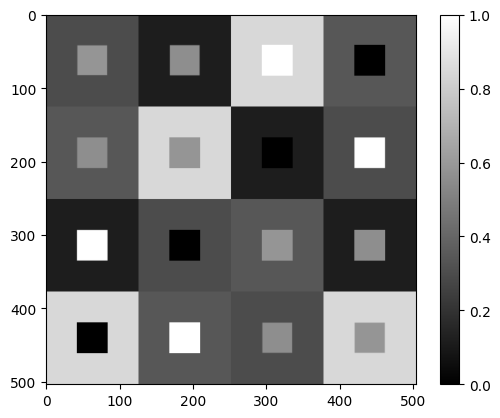

In [3]:
plt.imshow(gray_array, cmap="gray")
plt.colorbar()
plt.show()

In [4]:
# Make blurring operator
blur_sigma = np.array(5.0).astype(np.float64) # standard deviation of the blur
A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=blur_sigma)

# Generate synthetic data
np.random.seed(0)
b_true = A @ x_true
noise_sigma = 0.01
noise_var = noise_sigma**2
b = b_true + noise_sigma*np.random.normal(size=A.shape[0])
b_noisy = b.copy()

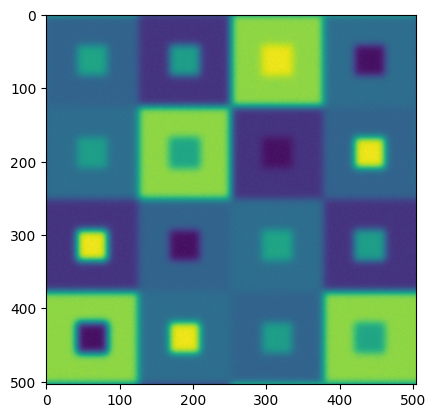

In [5]:
plt.imshow(b.reshape(img_shape))
plt.show()

# Set up solvers

In [6]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None


K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


#err_norm_sq = len(b) # in expectation

q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

ias_weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}


# Build solvers

gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
iasgks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all solvers

In [7]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

print("Finished GKS.")


1e-14
1e-14
1e-14
1e-14
1e-14
241.83386166779107
459.572592920379
562.2720870082497
631.1990964003736
655.573474101921
664.5767784446061
681.3782200596651
695.1441533811851
697.5580208948447
697.3237858149716
696.8963279875853
696.3158981153201
696.4278571791804
695.0363402747829
693.1053631780203
690.3166962230391
688.3286835102653
687.0713425813741
686.2952942892517
685.969558511944
685.8000894047907
685.6992159423061
685.6965343668227
685.7481447165513
685.7934428597403
685.8064687480077
685.7975484916788
685.7856074231431
685.7747117354195
685.7655640144841
685.7573941564311
685.7483897812679
685.7395596154737
685.7328229276484
685.7297866348875
685.7313623407496
685.7326329464327
685.7295065942931
685.7254878568779
685.7239182332295
685.7242679359932
685.7250179393045
685.725709349469
685.7258568500531
685.7254744580523
Finished GKS.


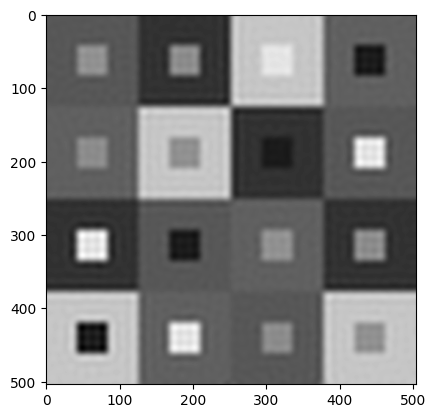

In [8]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray")
plt.show()

In [9]:
data = mmgks_solver.solve(n_iter=25, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

print("Finished S-GKS.")


resdata = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

print("Finished restarting S-GKS.")


recdata = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

print("Finished recycling S-GKS.")


pdata = mmgks_solver.solve_with_priorconditioning(n_iter=25, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

print("Finished PS-GKS.")

respdata = mmgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01}, restart_dim=5)

print("Finished PS-GKS.")


Augmented basis with initial guess!


18.362157061596694
26.326387705251506


29.236364998052682
29.80551370048387
28.28632342711677
27.79960883579031
28.43820493993268
29.190227254814154
29.762193038569446
29.904393460720712
29.590701269217515
29.412179140585756
29.282742253236645
29.709767416717156
30.521618017753717
31.44801804773475
32.47586472520761
33.2538390357695
34.10175077148042
34.81813088379375
35.6238274424763
36.331764568127674
37.0456620538007
37.78318627991423
38.35767930639288
Finished S-GKS.
Augmented basis with initial guess!


18.362157061596694
26.326387705251506
29.236364998052682
29.80551370048387
28.28632342711677
27.79960883579031
28.43820493993268
29.190227254814154
29.762193038569446
29.718188295458187
42.561047591749755
24.3511262960495
23.904365050057685
23.402188939472968
22.771699333579363
22.24217900171246
22.463178883535956
23.465947963496454
24.627512043357523
26.94824816830054
30.328293221313913
33.315015299713195
33.71390130654481
33.6531347781788
50.22459225776171
26.50392741610199
25.403000138922142
23.92023794325933
22.688840109583044
22.364406495515585
22.22537039626492
22.183919503164805
22.229669420527596
22.314499385183236
22.412738709694402
22.505299083044246
22.58283014217858
22.582318828006137
22.696697296436614
21.307664452789485
21.428774417165
22.010997713878336
22.244954445821186
22.092106779624505
22.06538444368636
22.32651237426777
22.809590113221613
23.281925392424398
23.7556736307566
24.04463937530214
Finished restarting S-GKS.
Augmented basis with initial guess!


18.362157061596694
26.326387705251506
29.236364998052682
29.80551370048387
28.28632342711677
27.79960883579031
28.43820493993268
29.190227254814154
29.762193038569446
29.904393460720712
29.590701269217515
29.412179140585756
29.282742253236645
29.709767416717156
30.521618017753717
31.44801804773475
32.47586472520761
33.2538390357695
34.10175077148042
34.81813088379375
35.6238274424763
36.331764568127674
37.0456620538007
37.78318627991423
38.35767930639288
39.05074665904763
40.04066664623135
41.545242703455266
43.501954070587054
45.98268182313009
48.7009539151481
52.11832049633227
55.481995898188444
58.015236000591
60.49783855068836
63.25905873799231
66.46888342484327
69.08009228338365
72.38453881775433
76.34106626032852
79.74582327782532
82.86733371987965
85.98873323364509
89.2627249538529
91.60319408378498
93.43428879763707
93.48190404724039
94.27127843584695
94.71382269199455
94.79720606036256
Finished recycling S-GKS.
Augmented basis with initial guess!


/home/jlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_squares/../../msolver.py:713: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
Finished PS-GKS.
Augmented basis with initial guess!


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
4.769074674451347
23.640502727757127
37.51955711348323
44.27650823879712
46.83616020943897
47.189206828978065
51.73975715428452
56.38905817925113
66.66378408497626
71.84405772537355
79.69496428324061
84.68595592685915
89.44326923681504
91.5347757626443
96.73104339761169
101.13471722027113
108.07724329719333
114.31297535924784
122.39606003233318
Finished PS-GKS.


In [10]:
data_ias = iasgks_solver.solve(n_iter=25, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01})

print("Finished S-GKS.")


resdata_ias = iasgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

print("Finished restarting S-GKS.")


recdata_ias = iasgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

print("Finished recycling S-GKS.")


pdata_ias = iasgks_solver.solve_with_priorconditioning(n_iter=25, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                                 regparam_kwargs={"eta":1.01})

print("Finished PS-GKS.")

respdata_ias = iasgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                                 regparam_kwargs={"eta":1.01}, restart_dim=5)

print("Finished PS-GKS.")


Augmented basis with initial guess!


275.0881970209426
449.86555078951847
552.7048070169752
661.5438960446876
810.5295347454387
976.6758900004904
1149.9887176295176
1290.8645592458543
1406.0997958485407
1514.5707330759142
1641.516227350852
1772.1223691630603
1801.100201526325
1906.4642938442225
2037.049307137225
2072.115606240291
2100.165831695357
2013.0127786909334
1995.9794623094792
1930.0897806239254
1942.3431944815864
1970.7781680756048
1985.6890273953484
2000.6922692773446
1997.6819374937759
Finished S-GKS.
Augmented basis with initial guess!


275.0881970209426
449.86555078951847
552.7048070169752
661.5438960446876
810.5295347454387
976.6758900004904
1149.9887176295176
1290.8645592458543
1406.0997958485407
1484.7689368415558
5208.475634132025
2782.3770356709238
2148.5395260572645
3040.2579704612554
4494.466006601025
4671.84336590698
4181.014727061134
3912.320786062565
4188.374560413557
4101.011639063133
3870.3753002748763
3601.77146312101
3455.241818245763
3363.8452542422774
13188.5418047118
31782.2754931673
4113.096022750817
7660.895216373196
7460.1384747876
7952.114220334947
8271.499968150909
9365.3947017777
9878.244373113594
10403.598151929502
10646.282557934099
10805.072717329911
11574.348117241898
12120.681149684178
20684.70545334142
20415.67401672518
2381.4705122958226
7540.623914984626
30423.91412201208
39856.26329196013
31901.864939017087
26797.40220896126
28689.378938637517
29154.00339476078
27940.843966476234
28718.254491681422
Finished restarting S-GKS.
Augmented basis with initial guess!


275.0881970209426
449.86555078951847
552.7048070169752
661.5438960446876
810.5295347454387
976.6758900004904
1149.9887176295176
1290.8645592458543
1406.0997958485407
1514.5707330759142
1641.516227350852
1772.1223691630603
1801.100201526325
1906.4642938442225
2037.049307137225
2072.115606240291
2100.165831695357
2013.0127786909334
1995.9794623094792
1930.0897806239254
1942.3431944815864
1970.7781680756048
1985.6890273953484
2000.6922692773446
1997.6819374937759
1976.9066093032307
1949.0572829277896
1938.811996611191
1924.4450162731748
1907.7391528214673
1889.084940496098
1880.683540453433
1876.121405218421
1873.5122899952048
1871.3481681970195
1869.0995168019167
1865.2128081420635
1858.2449722312995
1850.6355726449635
1843.9890567976115
1838.8562437343685
1834.9618039619131
1832.1497081405457
1830.2026787877655
1829.171471194187
1830.0388541735374
1832.0657703738934
1834.5526299588685
1836.3684571241206
1836.3213956488944
Finished recycling S-GKS.
Augmented basis with initial guess!


1e-14


/home/jlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_squares/../../msolver.py:713: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
Finished PS-GKS.
Augmented basis with initial guess!


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
181.63745822324285
1e-14
260.69771292447945
1e-14
312.1888977851878
1e-14
323.898991815076
1e-14
341.8056306407572
Finished PS-GKS.


# Plot

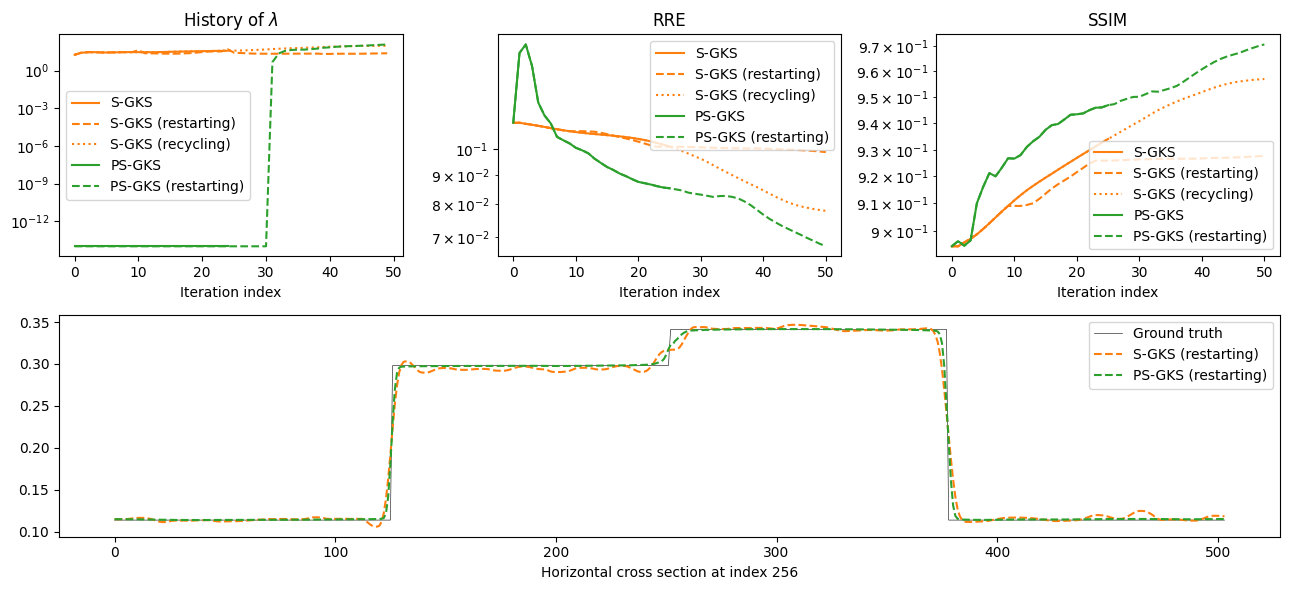

In [11]:
fig = plt.figure(figsize=(13,6))

gs = gridspec.GridSpec(2, 3, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C1")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C2")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 1])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C1")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C2")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 2])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C1")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C2")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()


ax4 = fig.add_subplot(gs[1, :]) 
ax4.plot(x_true.reshape(img_shape)[256,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(resdata["x"].reshape(img_shape)[256,:], label="S-GKS (restarting)", color="C1", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[256,:], label="PS-GKS (restarting)", color="C2", ls="--")
ax4.set_xlabel("Horizontal cross section at index 256")
ax4.legend()



fig.tight_layout()
#fig.savefig("2d_squares_performance.png", dpi=250, bbox_inches=None)
#fig.savefig("2d_squares_performance.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

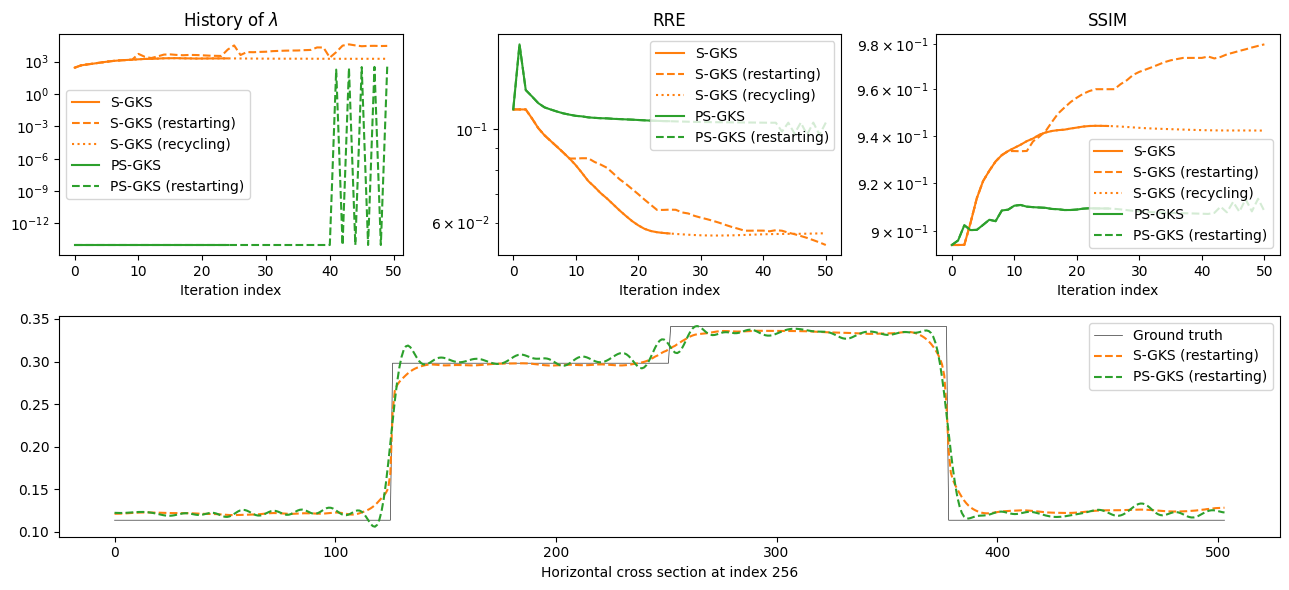

In [12]:
fig = plt.figure(figsize=(13,6))

gs = gridspec.GridSpec(2, 3, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.semilogy(data_ias["lambda_history"], label="S-GKS", color="C1")
ax1.semilogy(resdata_ias["lambda_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax1.semilogy(recdata_ias["lambda_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax1.semilogy(pdata_ias["lambda_history"], label="PS-GKS", color="C2")
ax1.semilogy(respdata_ias["lambda_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 1])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax2.semilogy(data_ias["rre_history"], label="S-GKS", color="C1")
ax2.semilogy(resdata_ias["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax2.semilogy(recdata_ias["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax2.semilogy(pdata_ias["rre_history"], label="PS-GKS", color="C2")
ax2.semilogy(respdata_ias["rre_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 2])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax3.semilogy(data_ias["ssim_history"], label="S-GKS", color="C1")
ax3.semilogy(resdata_ias["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax3.semilogy(recdata_ias["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax3.semilogy(pdata_ias["ssim_history"], label="PS-GKS", color="C2")
ax3.semilogy(respdata_ias["ssim_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()


ax4 = fig.add_subplot(gs[1, :]) 
ax4.plot(x_true.reshape(img_shape)[256,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(resdata_ias["x"].reshape(img_shape)[256,:], label="S-GKS (restarting)", color="C1", ls="--")
ax4.plot(respdata_ias["x"].reshape(img_shape)[256,:], label="PS-GKS (restarting)", color="C2", ls="--")
ax4.set_xlabel("Horizontal cross section at index 256")
ax4.legend()



fig.tight_layout()
#fig.savefig("2d_squares_performance.png", dpi=250, bbox_inches=None)
#fig.savefig("2d_squares_performance.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

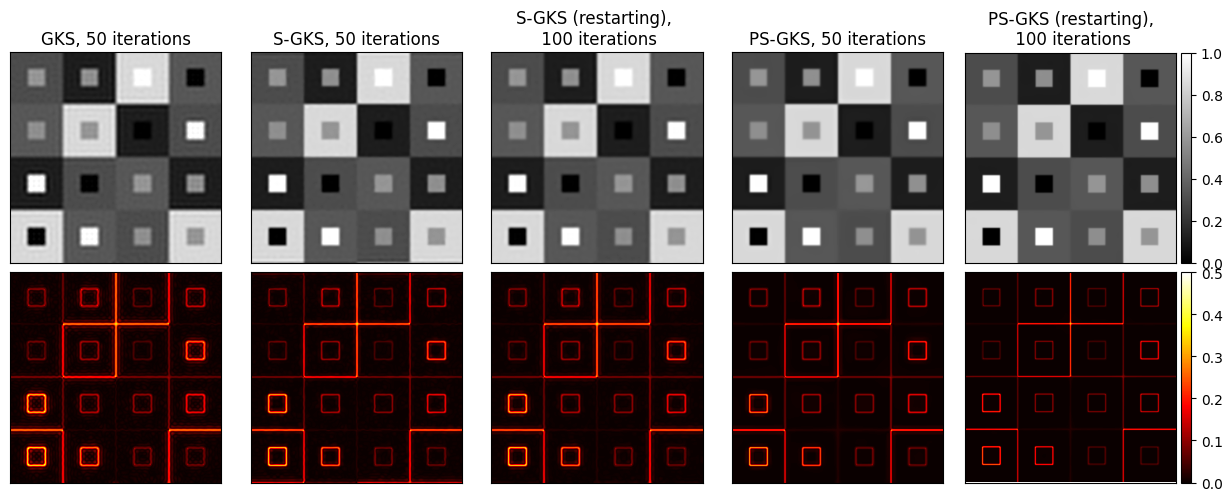

In [13]:
err_cmap = "hot"

vbound = 0.5

fig, axs = plt.subplots(2,5,figsize=(12.5,5))


# Tikhonov
axs[0,0].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("GKS, 50 iterations")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( vdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# S-GKS
axs[0,1].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("S-GKS, 50 iterations")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( data["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS (restarting)
axs[0,2].imshow(resdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS (restarting), \n 100 iterations")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( resdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS, 50 iterations")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])



# PS-GKS restarting
im = axs[0,4].imshow(respdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("PS-GKS (restarting),\n 100 iterations")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])
divider = make_axes_locatable(axs[0,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,4].imshow(np.abs(respdata["x"].reshape(img_shape) - x_true.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])
divider = make_axes_locatable(axs[1,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)


#fig.savefig("2d_squares_reconstructions.png", dpi=250, bbox_inches=None)
#fig.savefig("2d_squares_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)

fig.tight_layout()

plt.show()

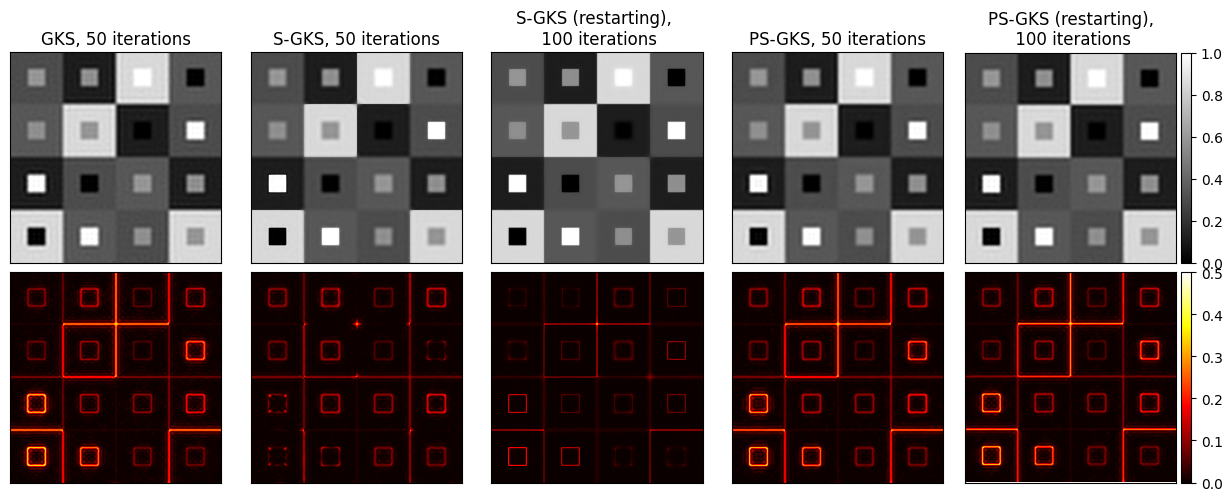

In [15]:
err_cmap = "hot"

vbound = 0.5

fig, axs = plt.subplots(2,5,figsize=(12.5,5))


# Tikhonov
axs[0,0].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("GKS, 50 iterations")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( vdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# S-GKS
axs[0,1].imshow(data_ias["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("S-GKS, 50 iterations")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( data_ias["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS (restarting)
axs[0,2].imshow(resdata_ias["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS (restarting), \n 100 iterations")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( resdata_ias["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata_ias["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS, 50 iterations")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata_ias["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])



# PS-GKS restarting
im = axs[0,4].imshow(respdata_ias["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("PS-GKS (restarting),\n 100 iterations")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])
divider = make_axes_locatable(axs[0,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,4].imshow(np.abs(respdata_ias["x"].reshape(img_shape) - x_true.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])
divider = make_axes_locatable(axs[1,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)


#fig.savefig("2d_squares_reconstructions.png", dpi=250, bbox_inches=None)
#fig.savefig("2d_squares_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)

fig.tight_layout()

plt.show()

In [ ]:
cmap = "seismic"
vbound = 0.018

fig, axs = plt.subplots(2,5,figsize=(12.5,5))

kk = 0

axs[0,0].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,0].set_title(f"S-GKS basis vector {kk+1}")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])
axs[1,0].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")



kk = 2
axs[0,1].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,1].set_title(f"S-GKS basis vector {kk+1}")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])
axs[1,1].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 9
axs[0,2].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,2].set_title(f"S-GKS basis vector {kk+1}")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])
axs[1,2].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 14
axs[0,3].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,3].set_title(f"S-GKS basis vector {kk+1}")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])
axs[1,3].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 19
im = axs[0,4].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,4].set_title(f"S-GKS basis vector {kk+1}")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])
divider = make_axes_locatable(axs[0,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,4].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])
axs[1,4].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")
divider = make_axes_locatable(axs[1,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)


fig.savefig("2d_squares_basis_vectors.png", dpi=250, bbox_inches=None)
fig.savefig("2d_squares_basis_vectors.eps", format="eps", dpi=250, bbox_inches=None)

fig.tight_layout()

plt.show()